# 04. `Dataset` 과 `DataLoader`

데이터 전체를 한 번에 넣지 않고 **미니배치**로 나눠서 학습한다.

- `Dataset` : "i번째 샘플이 무엇인가"를 정의 (`__len__`, `__getitem__`)
- `DataLoader` : 샘플을 모아 배치로 묶고, 섞고(shuffle), 반복한다

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(0)

## 1. `TensorDataset` — 이미 텐서가 있을 때

In [2]:
X = torch.arange(10, dtype=torch.float32).unsqueeze(1)   # (10, 1)
y = X * 2
ds = TensorDataset(X, y)
print("len:", len(ds), "| ds[3]:", ds[3])

loader = DataLoader(ds, batch_size=4, shuffle=True)
for xb, yb in loader:
    print(xb.shape, xb.squeeze(1).tolist())              # 마지막 배치는 2개

print("drop_last=True 배치 수:", len(DataLoader(ds, batch_size=4, drop_last=True)))

len: 10 | ds[3]: (tensor([3.]), tensor([6.]))
torch.Size([4, 1]) [6.0, 7.0, 1.0, 4.0]
torch.Size([4, 1]) [2.0, 0.0, 9.0, 8.0]
torch.Size([2, 1]) [3.0, 5.0]
drop_last=True 배치 수: 2


## 2. 커스텀 `Dataset`

`__len__`과 `__getitem__` 두 개만 구현하면 된다. `__getitem__`이 **샘플 하나**를 반환하면 `DataLoader`가 `torch.stack`으로 묶어 배치를 만든다.

In [3]:
class SineDataset(Dataset):
    def __init__(self, n):
        self.x = torch.rand(n, 1) * 6 - 3                  # [-3, 3)
        self.y = torch.sin(self.x) + 0.1 * torch.randn(n, 1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


ds = SineDataset(1000)
print("샘플 하나:", ds[0][0].shape, ds[0][1].shape)          # (1,), (1,)
xb, yb = next(iter(DataLoader(ds, batch_size=32, shuffle=True)))
print("배치    :", xb.shape, yb.shape)                       # (32, 1), (32, 1)

샘플 하나: torch.Size([1]) torch.Size([1])
배치    : torch.Size([32, 1]) torch.Size([32, 1])


## 3. Train / Validation 분할

In [4]:
train_ds, val_ds = random_split(ds, [800, 200], generator=torch.Generator().manual_seed(0))
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)    # 학습: 섞기
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)       # 검증: 섞을 필요 없음
print(len(train_ds), len(val_ds), "| train 배치 수:", len(train_loader))

800 200 | train 배치 수: 25


## 4. 표준 학습 루프 (함수로 정리)

에폭(epoch) = 학습 데이터를 한 바퀴 다 도는 것. 에폭마다 검증 손실을 보면서 과적합을 확인한다.

In [5]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total = 0.0
    for xb, yb in loader:
        total += loss_fn(model(xb), yb).item() * len(xb)
    return total / len(loader.dataset)


model = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(30):
    tr = train_one_epoch(model, train_loader, loss_fn, optimizer)
    va = evaluate(model, val_loader, loss_fn)
    if epoch % 5 == 0 or epoch == 29:
        print(f"epoch {epoch:2d}  train {tr:.4f}  val {va:.4f}")

epoch  0  train 0.1904  val 0.0558


epoch  5  train 0.0138  val 0.0170


epoch 10  train 0.0116  val 0.0113
epoch 15  train 0.0132  val 0.0114


epoch 20  train 0.0121  val 0.0103


epoch 25  train 0.0147  val 0.0129


epoch 29  train 0.0134  val 0.0118


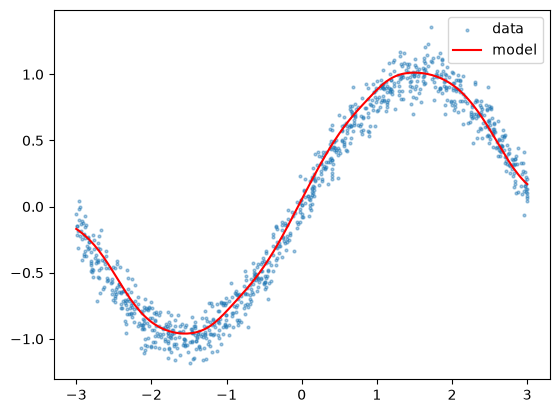

In [6]:
xs = torch.linspace(-3, 3, 200).unsqueeze(1)
with torch.no_grad():
    plt.scatter(ds.x, ds.y, s=4, alpha=0.4, label="data")
    plt.plot(xs, model(xs), color="red", label="model")
plt.legend()
plt.show()

## 5. 시퀀스 데이터: "다음 값 예측"용 (입력, 정답) 쌍 만들기

긴 시퀀스를 길이 `L`의 창(window)으로 자르고, 정답은 **한 칸 뒤로 민 것**으로 만든다.
언어 모델(RNN, GPT)이 학습하는 데이터가 정확히 이 구조다. `stride`는 창을 몇 칸씩 옮길지를 정한다.

In [7]:
class WindowDataset(Dataset):
    def __init__(self, seq, window, stride):
        self.inputs, self.targets = [], []
        for i in range(0, len(seq) - window, stride):
            self.inputs.append(seq[i : i + window])
            self.targets.append(seq[i + 1 : i + window + 1])

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]


seq = torch.arange(10)
wds = WindowDataset(seq, window=4, stride=2)
for i in range(len(wds)):
    x, y = wds[i]
    print("x:", x.tolist(), " → y:", y.tolist())

# 같은 결과를 한 줄로: unfold(차원, 크기, 간격)
chunks = seq.unfold(0, 4 + 1, 2)        # (N, window+1)
print(chunks[:, :-1].tolist(), chunks[:, 1:].tolist())

x: [0, 1, 2, 3]  → y: [1, 2, 3, 4]
x: [2, 3, 4, 5]  → y: [3, 4, 5, 6]
x: [4, 5, 6, 7]  → y: [5, 6, 7, 8]
[[0, 1, 2, 3], [2, 3, 4, 5], [4, 5, 6, 7]] [[1, 2, 3, 4], [3, 4, 5, 6], [5, 6, 7, 8]]


## 6. 길이가 다른 시퀀스: padding + `collate_fn`

문장마다 길이가 다르면 기본 동작(`torch.stack`)이 실패한다. `collate_fn`으로 **짧은 것을 PAD로 채워** 길이를 맞춘다.
이때 어디가 진짜 토큰인지 알려 주는 **mask**도 함께 만든다.

In [8]:
PAD = 0
seqs = [torch.tensor([5, 3, 8]), torch.tensor([2, 7]), torch.tensor([9, 1, 4, 6])]

try:
    next(iter(DataLoader(seqs, batch_size=3)))
except RuntimeError as e:
    print("기본 collate 실패:", str(e)[:80], "...")


def collate_pad(batch):
    lengths = torch.tensor([len(s) for s in batch])
    padded = pad_sequence(batch, batch_first=True, padding_value=PAD)     # (B, T_max)
    mask = torch.arange(padded.size(1))[None, :] < lengths[:, None]       # (B, T_max), True = 진짜 토큰
    return padded, lengths, mask


padded, lengths, mask = next(iter(DataLoader(seqs, batch_size=3, collate_fn=collate_pad)))
print(padded)
print(lengths)
print(mask)

기본 collate 실패: stack expects each tensor to be equal size, but got [3] at entry 0 and [2] at en ...
tensor([[5, 3, 8, 0],
        [2, 7, 0, 0],
        [9, 1, 4, 6]])
tensor([3, 2, 4])
tensor([[ True,  True,  True, False],
        [ True,  True, False, False],
        [ True,  True,  True,  True]])


손실을 계산할 때 PAD 위치는 빼야 한다. `cross_entropy`의 `ignore_index`(기본값 -100)에 해당하는 정답은 무시된다.

In [9]:
torch.manual_seed(0)
logits = torch.randn(3, 4, 10)                  # (B, T, 클래스 수)
targets = torch.randint(0, 10, (3, 4))
targets[~mask] = -100                           # PAD 위치는 정답 -100으로

loss = F.cross_entropy(logits.flatten(0, 1), targets.flatten())   # ignore_index=-100이 기본값
manual = F.cross_entropy(logits[mask], targets[mask])              # 진짜 토큰만 골라서 계산
print(loss.item(), manual.item())                                  # 같다

2.535764217376709 2.535764217376709
